<a href="https://colab.research.google.com/github/GuldenizKendigelen/Flight-Delays-Cancellations-Analysis-2019-2023-/blob/main/notebooks/flight_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projenin amacı ✈


Bu çalışmada, bir uçuşun varışta 15 dakikadan fazla rötar yapıp yapmayacağı tahmin edilmektedir. Tahmin için yalnızca uçuş öncesinde bilinen mesafe, havayolu, havalimanı, tarih ve planlanan kalkış saati bilgileri kullanılacaktır. İptal edilen, başka havalimanına yönlendirilen veya varış gecikmesi bilinmeyen uçuşlar çalışma kapsamına alınmayacaktır.

# Kütüphanelerin yüklenmesi


Veri hazırlama, model eğitimi, değerlendirme ve grafik araçlarını içeri aktarıyoruz.

In [ ]:
%pip -q install scikit-learn seaborn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    classification_report,
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay
)

from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
TARGET = "IS_DELAYED"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# CSV dosyasını okuyun


In [ ]:
FILE_PATH = "flights_sample_3m.csv"

df = pd.read_csv(FILE_PATH, low_memory=False)

# Sütun adlarını standartlaştır
df.columns = df.columns.str.strip().str.upper()

print("Satır sayısı:", len(df))
print("Sütun sayısı:", len(df.columns))

display(df.head())
print("Sütunlar:", df.columns.tolist())

Satır sayısı: 3000000
Sütun sayısı: 32


,FL_DATE,AIRLINE,AIRLINE_DOT,AIRLINE_CODE,DOT_CODE,FL_NUMBER,ORIGIN,ORIGIN_CITY,DEST,DEST_CITY,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,ELAPSED_TIME,AIR_TIME,DISTANCE,DELAY_DUE_CARRIER,DELAY_DUE_WEATHER,DELAY_DUE_NAS,DELAY_DUE_SECURITY,DELAY_DUE_LATE_AIRCRAFT
0,2019-01-09,United Air Lines Inc.,United Air Lines Inc.: UA,UA,19977,1562,FLL,"Fort Lauderdale, FL",EWR,"Newark, NJ",1155,1151.0,-4.0,19.0,1210.0,1443.0,4.0,1501,1447.0,-14.0,0.0,NaN,0.0,186.0,176.0,153.0,1065.0,NaN,NaN,NaN,NaN,NaN
1,2022-11-19,Delta Air Lines Inc.,Delta Air Lines Inc.: DL,DL,19790,1149,MSP,"Minneapolis, MN",SEA,"Seattle, WA",2120,2114.0,-6.0,9.0,2123.0,2232.0,38.0,2315,2310.0,-5.0,0.0,NaN,0.0,235.0,236.0,189.0,1399.0,NaN,NaN,NaN,NaN,NaN
2,2022-07-22,United Air Lines Inc.,United Air Lines Inc.: UA,UA,19977,459,DEN,"Denver, CO",MSP,"Minneapolis, MN",954,1000.0,6.0,20.0,1020.0,1247.0,5.0,1252,1252.0,0.0,0.0,NaN,0.0,118.0,112.0,87.0,680.0,NaN,NaN,NaN,NaN,NaN
3,2023-03-06,Delta Air Lines Inc.,Delta Air Lines Inc.: DL,DL,19790,2295,MSP,"Minneapolis, MN",SFO,"San Francisco, CA",1609,1608.0,-1.0,27.0,1635.0,1844.0,9.0,1829,1853.0,24.0,0.0,NaN,0.0,260.0,285.0,249.0,1589.0,0.0,0.0,24.0,0.0,0.0
4,2020-02-23,Spirit Air Lines,Spirit Air Lines: NK,NK,20416,407,MCO,"Orlando, FL",DFW,"Dallas/Fort Worth, TX",1840,1838.0,-2.0,15.0,1853.0,2026.0,14.0,2041,2040.0,-1.0,0.0,NaN,0.0,181.0,182.0,153.0,985.0,NaN,NaN,NaN,NaN,NaN


Sütunlar: ['FL_DATE', 'AIRLINE', 'AIRLINE_DOT', 'AIRLINE_CODE', 'DOT_CODE', 'FL_NUMBER', 'ORIGIN', 'ORIGIN_CITY', 'DEST', 'DEST_CITY', 'CRS_DEP_TIME', 'DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'WHEELS_OFF', 'WHEELS_ON', 'TAXI_IN', 'CRS_ARR_TIME', 'ARR_TIME', 'ARR_DELAY', 'CANCELLED', 'CANCELLATION_CODE', 'DIVERTED', 'CRS_ELAPSED_TIME', 'ELAPSED_TIME', 'AIR_TIME', 'DISTANCE', 'DELAY_DUE_CARRIER', 'DELAY_DUE_WEATHER', 'DELAY_DUE_NAS', 'DELAY_DUE_SECURITY', 'DELAY_DUE_LATE_AIRCRAFT']


# Veri kalitesi kontrolü

Gerekli sütunları kontrol edin

In [ ]:
# Havayolu alanı farklı adlandırılmışsa standartlaştır.
if "AIRLINE" not in df.columns:
    for alternative in [
        "OP_UNIQUE_CARRIER",
        "OP_CARRIER",
        "UNIQUE_CARRIER"
    ]:
        if alternative in df.columns:
            df = df.rename(columns={alternative: "AIRLINE"})
            break

required_columns = [
    "FL_DATE",
    "ARR_DELAY",
    "CANCELLED",
    "DIVERTED",
    "DISTANCE"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"CSV dosyasında gerekli sütunlar eksik: {missing_columns}"
    )

optional_columns = [
    "AIRLINE", "ORIGIN", "DEST", "CRS_DEP_TIME"
]

print("Gerekli sütunlar mevcut.")
print(
    "Kullanılabilen ek sütunlar:",
    [col for col in optional_columns if col in df.columns]
)

Gerekli sütunlar mevcut.
Kullanılabilen ek sütunlar: ['AIRLINE', 'ORIGIN', 'DEST', 'CRS_DEP_TIME']


Veri kalitesini kontrol edin

In [ ]:
print("Başlangıç satır sayısı:", len(df))

missing_summary = (
    df.isna()
      .mean()
      .mul(100)
      .round(2)
      .sort_values(ascending=False)
      .to_frame("Eksik_yuzde")
)

display(missing_summary)

numeric_columns = [
    "ARR_DELAY", "CANCELLED", "DIVERTED", "DISTANCE"
]

if "CRS_DEP_TIME" in df.columns:
    numeric_columns.append("CRS_DEP_TIME")

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Tarih metinlerinin yıl-ay-gün biçiminde olduğu varsayılır.
df["FL_DATE"] = pd.to_datetime(
    df["FL_DATE"],
    errors="coerce"
).dt.normalize()

print("Okunamayan tarih sayısı:", df["FL_DATE"].isna().sum())

Başlangıç satır sayısı: 3000000


,Eksik_yuzde
CANCELLATION_CODE,97.36
DELAY_DUE_LATE_AIRCRAFT,82.20
DELAY_DUE_CARRIER,82.20
DELAY_DUE_SECURITY,82.20
DELAY_DUE_NAS,82.20
DELAY_DUE_WEATHER,82.20
ARR_DELAY,2.87
ELAPSED_TIME,2.87
AIR_TIME,2.87
WHEELS_ON,2.66


Okunamayan tarih sayısı: 0


Şimdi kapsam dışındaki kayıtları çıkarın:

In [ ]:
initial_count = len(df)

df = df.loc[
    df["CANCELLED"].eq(0)
    & df["DIVERTED"].eq(0)
    & df["ARR_DELAY"].notna()
    & df["FL_DATE"].notna()
    & df["DISTANCE"].gt(0)
].copy()

df = df.sort_values("FL_DATE").reset_index(drop=True)

if df.empty:
    raise ValueError(
        "Filtrelerden sonra veri kalmadı. Tarih ve sayısal alanları kontrol edin."
    )

print("Çıkarılan satır:", initial_count - len(df))
print("Kalan satır:", len(df))
print("Başlangıç tarihi:", df["FL_DATE"].min())
print("Bitiş tarihi:", df["FL_DATE"].max())

Çıkarılan satır: 86198
Kalan satır: 2913802
Başlangıç tarihi: 2019-01-01 00:00:00
Bitiş tarihi: 2023-08-31 00:00:00


# Hedef değişkenin oluşturulması


In [ ]:
df[TARGET] = (df["ARR_DELAY"] > 15).astype(int)

target_summary = (
    df[TARGET]
      .value_counts()
      .reindex([0, 1], fill_value=0)
      .to_frame("Ucus_sayisi")
)

target_summary["Oran_yuzde"] = (
    target_summary["Ucus_sayisi"] / len(df) * 100
).round(2)

target_summary.index = [
    "Rötarsız: ≤15 dakika",
    "Rötarlı: >15 dakika"
]

display(target_summary)

,Ucus_sayisi,Oran_yuzde
Rötarsız: ≤15 dakika,2398513,82.32
Rötarlı: >15 dakika,515289,17.68


Hedef dağılımını görselleştirin

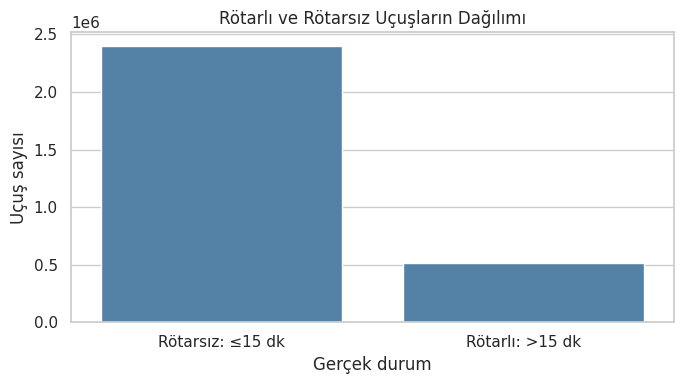

In [ ]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x=TARGET,
    color="steelblue"
)

plt.xticks(
    [0, 1],
    ["Rötarsız: ≤15 dk", "Rötarlı: >15 dk"]
)

plt.title("Rötarlı ve Rötarsız Uçuşların Dağılımı")
plt.xlabel("Gerçek durum")
plt.ylabel("Uçuş sayısı")
plt.tight_layout()
plt.show()

# Keşifsel veri analizi

Aylık rötar oranını da inceleyin:

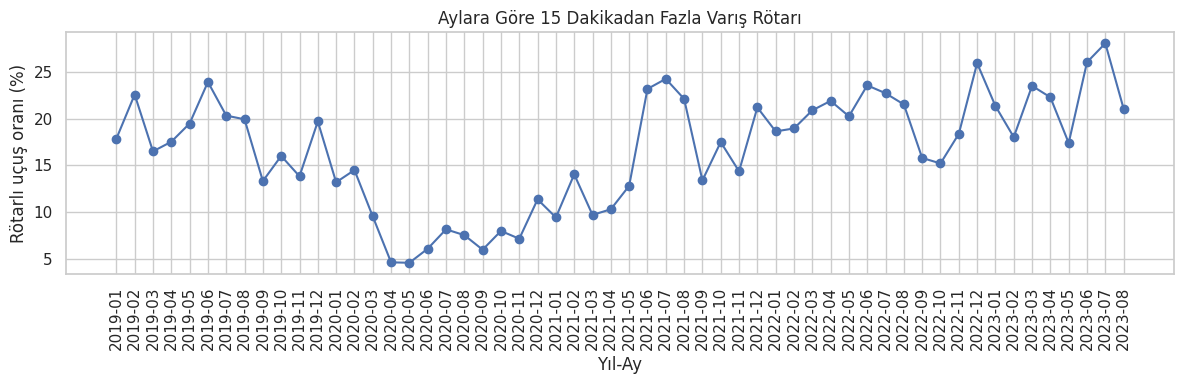

In [ ]:
monthly_rate = (
    df.groupby(df["FL_DATE"].dt.to_period("M"))[TARGET]
      .agg(["mean", "size"])
      .reset_index()
)

monthly_rate["FL_DATE"] = monthly_rate["FL_DATE"].astype(str)
monthly_rate["Rotar_orani_yuzde"] = monthly_rate["mean"] * 100

plt.figure(figsize=(12, 4))

plt.plot(
    monthly_rate["FL_DATE"],
    monthly_rate["Rotar_orani_yuzde"],
    marker="o"
)

plt.title("Aylara Göre 15 Dakikadan Fazla Varış Rötarı")
plt.xlabel("Yıl-Ay")
plt.ylabel("Rötarlı uçuş oranı (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Özelliklerin hazırlanması

Uçuş öncesi özellikleri hazırlayın

In [ ]:
df["MONTH"] = df["FL_DATE"].dt.month
df["DAY_OF_WEEK"] = df["FL_DATE"].dt.dayofweek

numeric_features = ["DISTANCE"]

categorical_features = [
    col for col in ["AIRLINE", "ORIGIN", "DEST"]
    if col in df.columns
]

categorical_features += ["MONTH", "DAY_OF_WEEK"]

if "CRS_DEP_TIME" in df.columns:
    t = df["CRS_DEP_TIME"]

    valid_time = (
        (
            t.between(0, 2359)
            & t.mod(100).lt(60)
            & t.mod(1).eq(0)
        )
        | t.eq(2400)
    )

    df["DEP_HOUR"] = ((t // 100) % 24).where(valid_time)
    categorical_features.append("DEP_HOUR")

# Tamamen boş kategorik alanları kullanma.
categorical_features = [
    col for col in categorical_features
    if df[col].notna().any()
]

for col in categorical_features:
    df[col] = df[col].apply(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

features = numeric_features + categorical_features

print("Model girdileri:", features)

Model girdileri: ['DISTANCE', 'AIRLINE', 'ORIGIN', 'DEST', 'MONTH', 'DAY_OF_WEEK', 'DEP_HOUR']


# Eğitim, doğrulama ve test ayrımı


Veriyi zamana göre ayıralim---
Eski uçuşlardan öğrenip yeni uçuşlari değerlendireceğiz.

In [ ]:
dates = np.sort(df["FL_DATE"].unique())

if len(dates) < 20:
    raise ValueError(
        "Zamana göre ayırmak için en az 20 farklı tarih gerekli."
    )

train_end = pd.Timestamp(dates[int(len(dates) * 0.70)])
valid_end = pd.Timestamp(dates[int(len(dates) * 0.85)])

train_df = df.loc[
    df["FL_DATE"] < train_end
].copy()

valid_df = df.loc[
    (df["FL_DATE"] >= train_end)
    & (df["FL_DATE"] < valid_end)
].copy()

test_df = df.loc[
    df["FL_DATE"] >= valid_end
].copy()

# Eğitim bölümünde tamamen boş kalan ek girdileri çıkar.
categorical_features = [
    col for col in categorical_features
    if train_df[col].notna().any()
]

features = numeric_features + categorical_features

X_train = train_df[features]
y_train = train_df[TARGET]

X_valid = valid_df[features]
y_valid = valid_df[TARGET]

X_test = test_df[features]
y_test = test_df[TARGET]

split_summary = []

for name, part in [
    ("Eğitim", train_df),
    ("Doğrulama", valid_df),
    ("Test", test_df)
]:
    if part[TARGET].nunique() != 2:
        raise ValueError(
            f"{name} bölümünde rötarlı ve rötarsız uçuşlar birlikte bulunmalı."
        )

    split_summary.append({
        "Bolum": name,
        "Ucus_sayisi": len(part),
        "Ilk_tarih": part["FL_DATE"].min().date(),
        "Son_tarih": part["FL_DATE"].max().date(),
        "Rotar_orani_yuzde": round(part[TARGET].mean() * 100, 2)
    })

display(pd.DataFrame(split_summary))

,Bolum,Ucus_sayisi,Ilk_tarih,Son_tarih,Rotar_orani_yuzde
0,Eğitim,1958751,2019-01-01,2022-04-06,15.91
1,Doğrulama,479946,2022-04-07,2022-12-18,19.82
2,Test,475105,2022-12-19,2023-08-31,22.84


# Veri ön işleme

Ön işleme sistemini oluşturun

In [ ]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Sınıflandırma modellerinin kurulması

In [ ]:
models = {
    "Referans": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DummyClassifier(strategy="prior"))
    ]),

    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            class_weight="balanced",
            max_iter=1000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=150,
            max_depth=16,
            min_samples_leaf=10,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
}

Model	Kullanım amacı
Referans	Basit bir başlangıç performansı sağlamak
Logistic Regression	Temel sınıflandırma modeli oluşturmak
Random Forest	Daha karmaşık ilişkileri öğrenmek

# Modellerin karşılaştırılması

In [ ]:
validation_rows = []
valid_probabilities = {}

for name, model in models.items():
    print("Eğitiliyor:", name)

    model.fit(X_train, y_train)

    probability = model.predict_proba(X_valid)[:, 1]
    prediction = (probability >= 0.50).astype(int)

    valid_probabilities[name] = probability

    validation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, prediction),
        "Precision": precision_score(
            y_valid, prediction, zero_division=0
        ),
        "Recall": recall_score(
            y_valid, prediction, zero_division=0
        ),
        "F1": f1_score(
            y_valid, prediction, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_valid, probability),
        "Average_Precision": average_precision_score(
            y_valid, probability
        )
    })

results = pd.DataFrame(validation_rows).sort_values(
    "Average_Precision",
    ascending=False
)

display(results.round(3))

Eğitiliyor: Referans
Eğitiliyor: Logistic Regression
Eğitiliyor: Random Forest


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Average_Precision
2,Random Forest,0.597,0.276,0.635,0.384,0.654,0.314
1,Logistic Regression,0.604,0.277,0.619,0.383,0.650,0.305
0,Referans,0.802,0.000,0.000,0.000,0.500,0.198


| Metrik | Cevapladığı soru |
|---|---|
| Accuracy | Tüm uçuşların ne kadarı doğru sınıflandırıldı? |
| Precision | Rötarlı dediklerimizin ne kadarı gerçekten rötarlı? |
| Recall | Gerçek rötarların ne kadarını yakaladık? |
| F1 | Precision ve recall dengesi nasıl? |
| ROC-AUC | Model iki sınıfı ne kadar iyi ayırıyor? |
| Average Precision | Rötarlı sınıf için precision-recall performansı nasıl? |

Model karşılaştırma grafiğini oluşturun

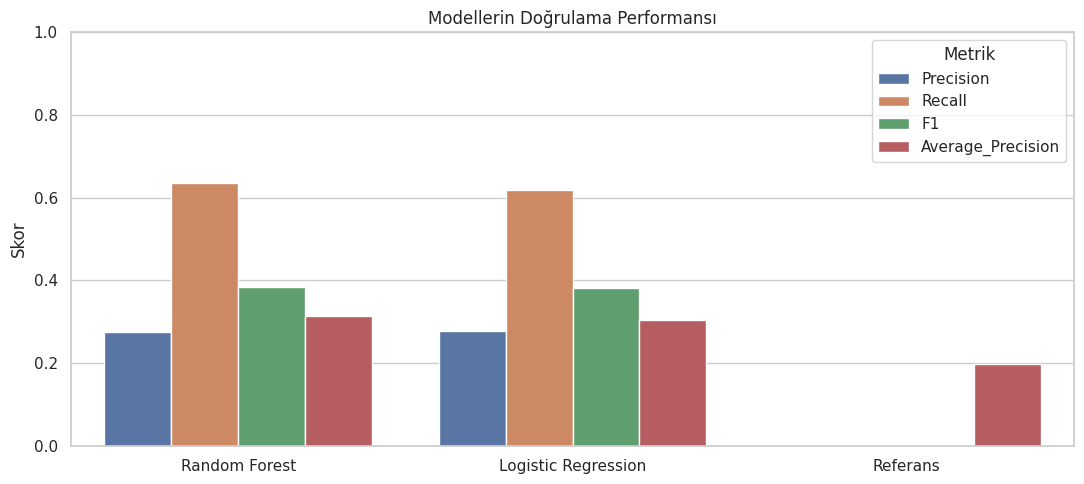

In [ ]:
comparison = results.melt(
    id_vars="Model",
    value_vars=[
        "Precision", "Recall", "F1", "Average_Precision"
    ],
    var_name="Metrik",
    value_name="Skor"
)

plt.figure(figsize=(11, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="Skor",
    hue="Metrik"
)

plt.ylim(0, 1)
plt.title("Modellerin Doğrulama Performansı")
plt.xlabel("")
plt.ylabel("Skor")
plt.tight_layout()
plt.show()

# Karar eşiğinin seçilmesi

In [ ]:
candidate_results = results.loc[
    results["Model"] != "Referans"
]

best_name = candidate_results.iloc[0]["Model"]
best_model = models[best_name]

valid_probability = valid_probabilities[best_name]

precision_values, recall_values, thresholds = (
    precision_recall_curve(y_valid, valid_probability)
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / np.maximum(
        precision_values[:-1] + recall_values[:-1],
        1e-12
    )
)

best_index = int(np.argmax(f1_values))
best_threshold = float(thresholds[best_index])

print("Seçilen model:", best_name)
print("Seçilen eşik:", round(best_threshold, 3))
print("Doğrulama F1:", round(f1_values[best_index], 3))

Seçilen model: Random Forest
Seçilen eşik: 0.503
Doğrulama F1: 0.385


# Test performansının değerlendirilmesi

In [ ]:
test_probability = best_model.predict_proba(X_test)[:, 1]

test_prediction = (
    test_probability >= best_threshold
).astype(int)

test_results = pd.Series({
    "Accuracy": accuracy_score(y_test, test_prediction),
    "Precision": precision_score(
        y_test, test_prediction, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_prediction, zero_division=0
    ),
    "F1": f1_score(
        y_test, test_prediction, zero_division=0
    ),
    "ROC_AUC": roc_auc_score(y_test, test_probability),
    "Average_Precision": average_precision_score(
        y_test, test_probability
    )
})

display(test_results.round(3).to_frame("Test_skoru"))

print(classification_report(
    y_test,
    test_prediction,
    target_names=["Rötarsız: ≤15 dk", "Rötarlı: >15 dk"],
    zero_division=0
))

,Test_skoru
Accuracy,0.574
Precision,0.301
Recall,0.656
F1,0.413
ROC_AUC,0.645
Average_Precision,0.347


                  precision    recall  f1-score   support

Rötarsız: ≤15 dk       0.84      0.55      0.67    366607
 Rötarlı: >15 dk       0.30      0.66      0.41    108498

        accuracy                           0.57    475105
       macro avg       0.57      0.60      0.54    475105
    weighted avg       0.72      0.57      0.61    475105



# Değişkenlerin tahmine katkısı

,Degisken,Performans_kaybi,Standart_sapma
6,DEP_HOUR,0.0700,0.0095
4,MONTH,0.0428,0.0075
1,AIRLINE,0.0294,0.0096
2,ORIGIN,0.0099,0.0039
0,DISTANCE,0.0064,0.0018
5,DAY_OF_WEEK,0.0056,0.0013
3,DEST,0.0030,0.0013


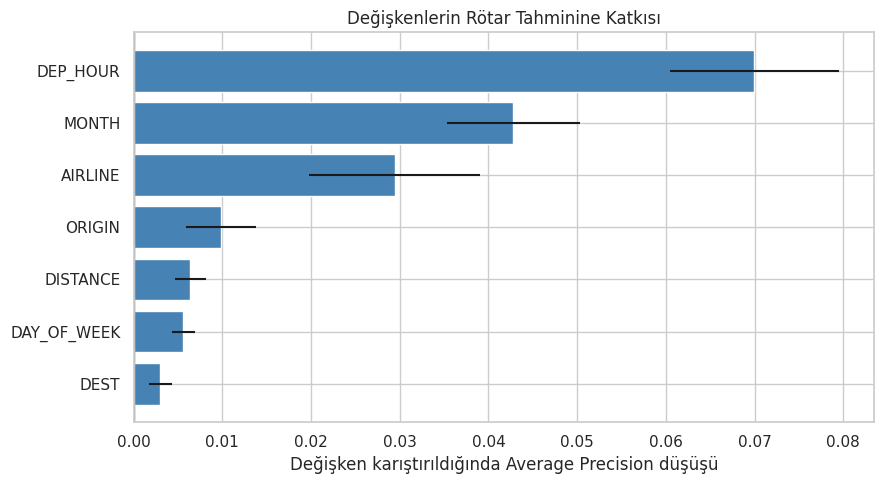

In [ ]:
importance_X = X_valid.sample(
    n=min(3000, len(X_valid)),
    random_state=RANDOM_STATE
)

importance_y = y_valid.loc[importance_X.index]

importance = permutation_importance(
    best_model,
    importance_X,
    importance_y,
    scoring="average_precision",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Degisken": features,
    "Performans_kaybi": importance.importances_mean,
    "Standart_sapma": importance.importances_std
}).sort_values("Performans_kaybi", ascending=False)

display(importance_df.round(4))

plt.figure(figsize=(9, 5))

plt.barh(
    importance_df["Degisken"],
    importance_df["Performans_kaybi"],
    xerr=importance_df["Standart_sapma"],
    color="steelblue"
)

plt.gca().invert_yaxis()
plt.axvline(0, color="gray", linewidth=1)
plt.title("Değişkenlerin Rötar Tahminine Katkısı")
plt.xlabel("Değişken karıştırıldığında Average Precision düşüşü")
plt.ylabel("")
plt.tight_layout()
plt.show()

# Örnek uçuş tahminleri

In [ ]:
example_X = X_test.sample(
    n=min(10, len(X_test)),
    random_state=RANDOM_STATE
)

example_scores = best_model.predict_proba(example_X)[:, 1]

example_results = example_X.copy()

example_results["Rotar_risk_skoru"] = np.round(
    example_scores, 3
)

example_results["Tahmin"] = np.where(
    example_scores >= best_threshold,
    "15 dakikadan fazla rötar",
    "En fazla 15 dakika gecikme"
)

example_results["Gercek_durum"] = np.where(
    y_test.loc[example_X.index].to_numpy() == 1,
    "15 dakikadan fazla rötar",
    "En fazla 15 dakika gecikme"
)

display(example_results)

,DISTANCE,AIRLINE,ORIGIN,DEST,MONTH,DAY_OF_WEEK,DEP_HOUR,Rotar_risk_skoru,Tahmin,Gercek_durum
2810579,2603.0,Alaska Airlines Inc.,HNL,PDX,7,0,15,0.527,15 dakikadan fazla rötar,15 dakikadan fazla rötar
2771233,868.0,American Airlines Inc.,DFW,PHX,6,0,12,0.552,15 dakikadan fazla rötar,En fazla 15 dakika gecikme
2555705,2398.0,United Air Lines Inc.,SFO,HNL,2,4,9,0.501,En fazla 15 dakika gecikme,En fazla 15 dakika gecikme
2835943,2454.0,United Air Lines Inc.,LAX,EWR,7,6,11,0.536,15 dakikadan fazla rötar,En fazla 15 dakika gecikme
2722033,2860.0,American Airlines Inc.,PHX,KOA,5,2,10,0.489,En fazla 15 dakika gecikme,En fazla 15 dakika gecikme
2455763,2182.0,Delta Air Lines Inc.,SEA,ATL,12,3,12,0.465,En fazla 15 dakika gecikme,15 dakikadan fazla rötar
2528442,1532.0,Delta Air Lines Inc.,SAN,MSP,2,3,13,0.475,En fazla 15 dakika gecikme,En fazla 15 dakika gecikme
2861609,1999.0,Southwest Airlines Co.,BWI,PHX,8,5,20,0.561,15 dakikadan fazla rötar,En fazla 15 dakika gecikme
2554605,2640.0,Alaska Airlines Inc.,SEA,OGG,2,4,8,0.485,En fazla 15 dakika gecikme,15 dakikadan fazla rötar
2633781,602.0,United Air Lines Inc.,DEN,PHX,4,4,15,0.513,15 dakikadan fazla rötar,En fazla 15 dakika gecikme


# Sonuçların yorumlanması

In [ ]:
print(
    f"Bu çalışmada uçuşların varışta 15 dakikadan fazla "
    f"rötar yapıp yapmayacağını tahmin eden sınıflandırma "
    f"modelleri kurulmuştur.\n\n"

    f"Doğrulama verisindeki Average Precision sonucuna göre "
    f"{best_name} modeli seçilmiştir.\n\n"

    f"Test verisinde gerçek rötarlı uçuşların "
    f"%{test_results['Recall'] * 100:.1f}'i yakalanmıştır. "
    f"Rötarlı olarak işaretlenen uçuşların "
    f"%{test_results['Precision'] * 100:.1f}'i gerçekten "
    f"15 dakikadan fazla gecikmiştir.\n\n"

    f"Test F1 skoru {test_results['F1']:.3f}, "
    f"ROC-AUC değeri {test_results['ROC_AUC']:.3f} ve "
    f"Average Precision değeri "
    f"{test_results['Average_Precision']:.3f} bulunmuştur."
)

Bu çalışmada uçuşların varışta 15 dakikadan fazla rötar yapıp yapmayacağını tahmin eden sınıflandırma modelleri kurulmuştur.

Doğrulama verisindeki Average Precision sonucuna göre Random Forest modeli seçilmiştir.

Test verisinde gerçek rötarlı uçuşların %65.6'i yakalanmıştır. Rötarlı olarak işaretlenen uçuşların %30.1'i gerçekten 15 dakikadan fazla gecikmiştir.

Test F1 skoru 0.413, ROC-AUC değeri 0.645 ve Average Precision değeri 0.347 bulunmuştur.
